# Spectral computation and exact endpoints

The singular values of $D_d$ define the positive eigenvalues of $D_d^\top D_d$. Once the spectral basis is constructed, degrees-of-freedom and smoothness traces are inexpensive to evaluate for many $\lambda$ values.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Publication styling only; numerical estimates and metrics are unchanged.
af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")

from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


## Penalty eigenvalues

The rank is n−d for 1≤d<n in exact arithmetic. Very high d can be poorly conditioned, so numerical nullities should not be inferred naively from floating-point eigenvalues.

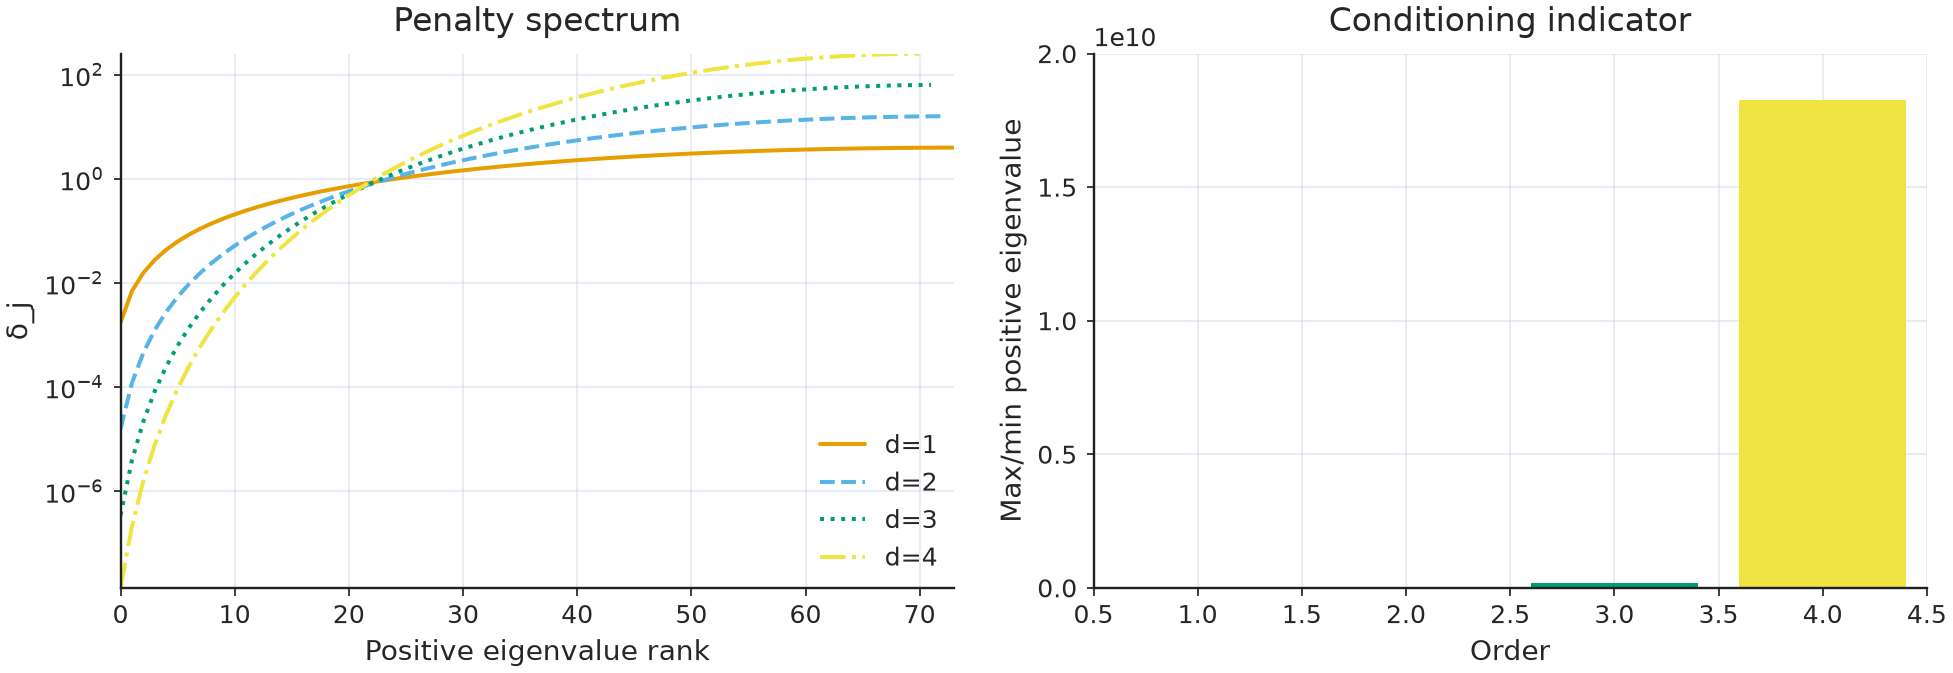

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from trendestimation import TrendSmoother
n=75;orders=[1,2,3,4]
fig,axs=plt.subplots(1,2,figsize=(11,4))
for d in orders:
    sm=TrendSmoother(n,d);positive=sm.eigenvalues[:n-d]
    axs[0].semilogy(np.sort(positive),label=f"d={d}")
    axs[1].bar(d,float(positive.max()/positive.min()))
axs[0].legend();axs[0].set(xlabel="Positive eigenvalue rank",ylabel="δ_j",title="Penalty spectrum")
axs[1].set(xlabel="Order",ylabel="Max/min positive eigenvalue",title="Conditioning indicator")
fig.tight_layout();plt.show()

## Spectral attenuation

The transfer factors $1/(1+\lambda\delta_j)$ shrink penalized directions while preserving the exact null space.

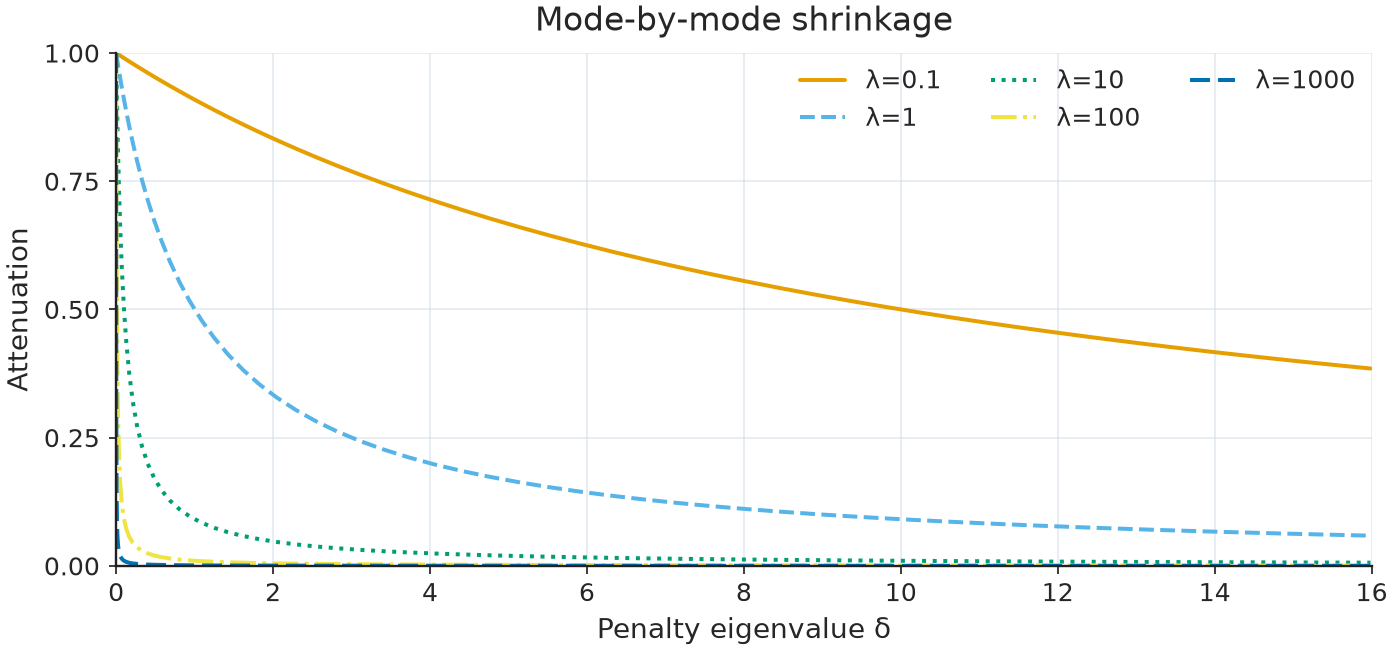

In [3]:
sm=TrendSmoother(n,2)
fig,ax=plt.subplots(figsize=(9,3.7))
for lam in [.1,1,10,100,1000]:
    ax.plot(np.sort(sm.eigenvalues),1/(1+lam*np.sort(sm.eigenvalues)),label=f"λ={lam}")
ax.set(xlabel="Penalty eigenvalue δ",ylabel="Attenuation",title="Mode-by-mode shrinkage")
ax.legend(ncol=3);plt.show()

## Effective degrees of freedom and normalized smoothness

The normalized index is S=(n−tr H)/(n−d), with exact endpoints S(0)=0 and S(∞)=1. Plot both curves and verify the boundary expressions.

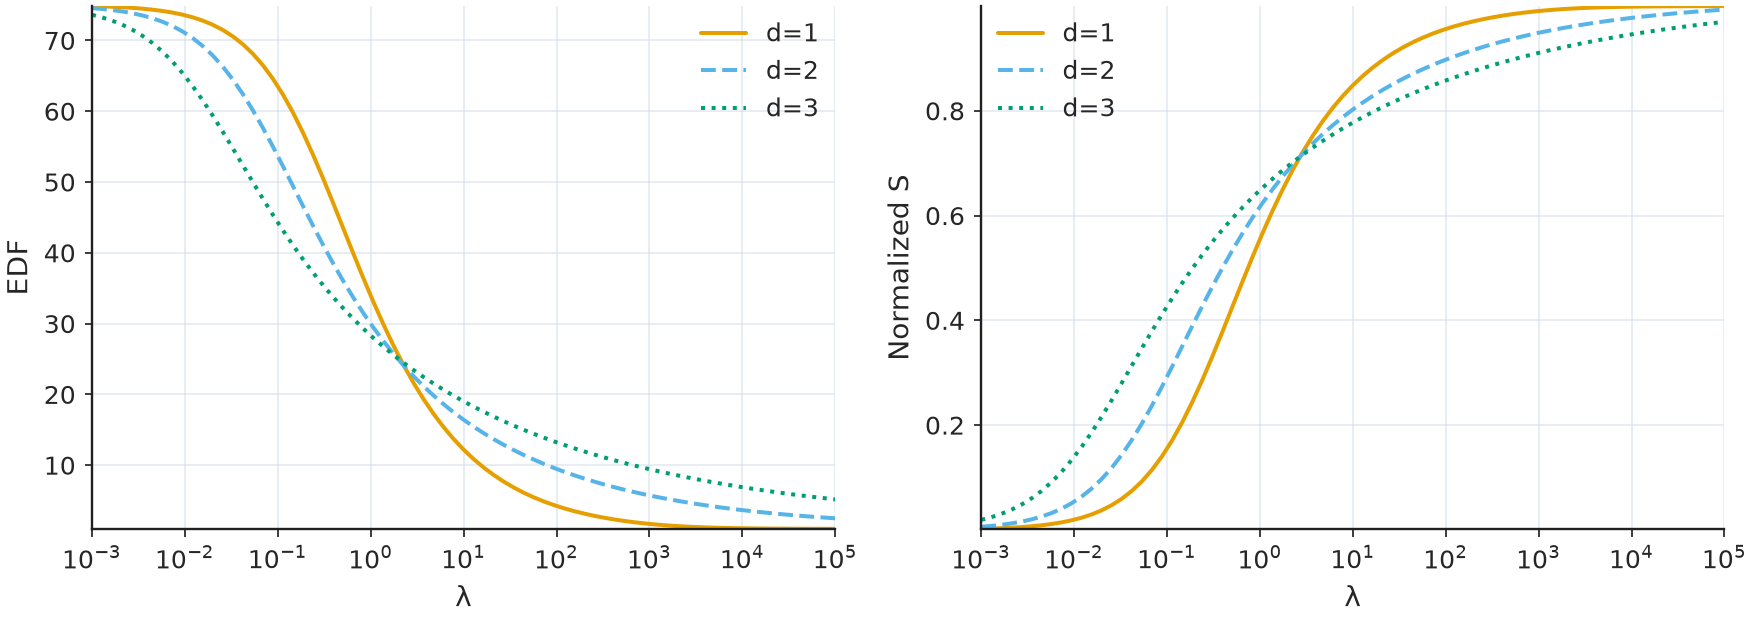

In [4]:
lambdas=np.geomspace(.001,1e5,75)
fig,axs=plt.subplots(1,2,figsize=(10,3.7))
for d in [1,2,3]:
    model=TrendSmoother(n,d)
    edf=np.asarray([model.degrees_of_freedom(float(x)) for x in lambdas])
    smooth=np.asarray([model.smoothness(float(x)) for x in lambdas])
    axs[0].semilogx(lambdas,edf,label=f"d={d}")
    axs[1].semilogx(lambdas,smooth,label=f"d={d}")
    assert model.degrees_of_freedom(float("inf"))==d
axs[0].set(xlabel="λ",ylabel="EDF");axs[1].set(xlabel="λ",ylabel="Normalized S")
axs[0].legend();axs[1].legend();fig.tight_layout();plt.show()

## Spectral likelihood and variance estimates

The Gaussian MLE model implies $\lambda=\sigma_\varepsilon^2/\sigma_\eta^2$: observation-noise variance divided by the latent **order-$d$ difference** variance. For each fixed positive penalty, profiling the Gaussian likelihood produces both variance estimates from the positive-penalty spectral coordinates. Their trajectories across penalties are **profile values**, not confidence bands; the exact infinite-penalty limit forces the difference variance to zero.

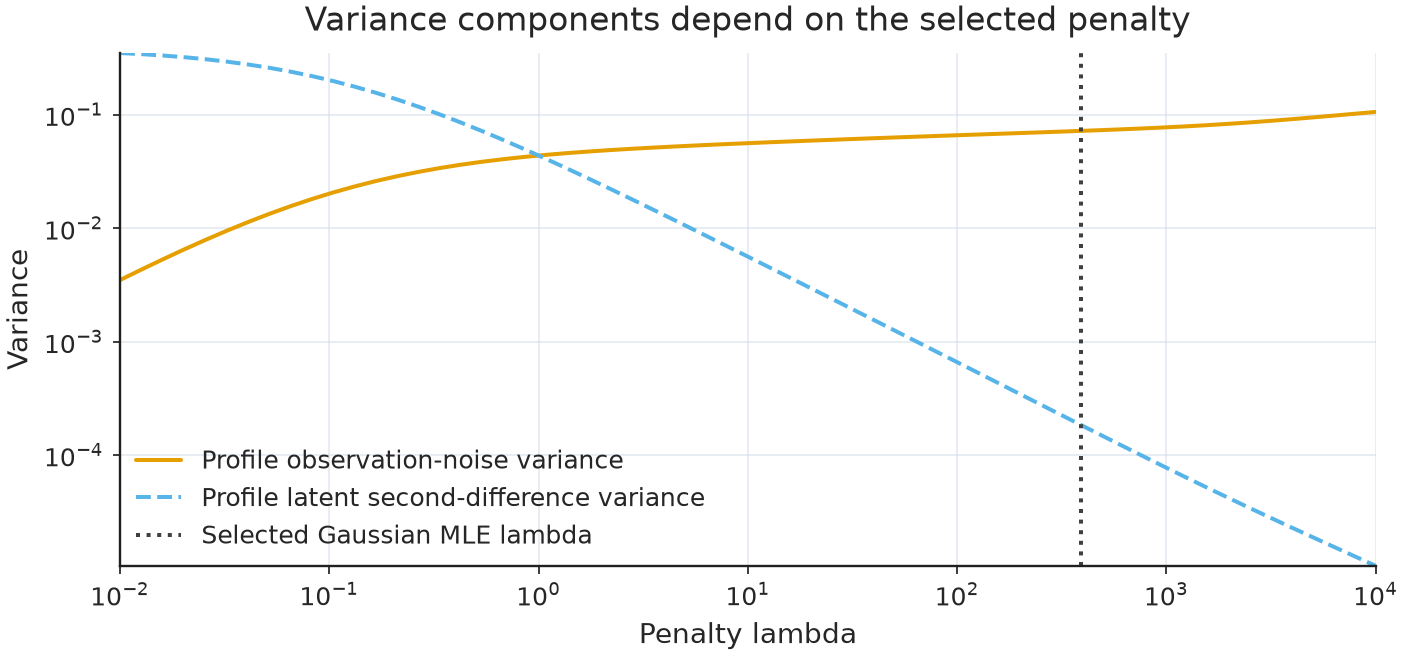

Selected lambda: 390.7063440777682
Observation variance: 0.07206993018582701
Difference variance: 0.00018446060904371144


In [5]:
from trendestimation import select_lambda, estimate_variance_components

rng = np.random.default_rng(610)
time = np.arange(n)
series = 0.025*time + 0.4*np.sin(time/10) + rng.normal(0, 0.3, n)
model = TrendSmoother(n, order=2)
choice = select_lambda(model, series, criterion="mle", mu=0.0)
grid = np.geomspace(0.01, 1e4, 60)
profiles = [
    estimate_variance_components(model, series, lambda_=float(lam), mu=0.0)
    for lam in grid
]
fig, ax = plt.subplots(figsize=(9, 3.7))
ax.loglog(grid, [v.observation_variance for v in profiles],
          label="Profile observation-noise variance")
ax.loglog(grid, [v.difference_variance for v in profiles],
          label="Profile latent second-difference variance")
if np.isfinite(choice.lambda_):
    ax.axvline(choice.lambda_, color="0.25", linestyle=":",
               label="Selected Gaussian MLE lambda")
ax.set(xlabel="Penalty lambda", ylabel="Variance",
       title="Variance components depend on the selected penalty")
ax.legend()
plt.show()
selected = estimate_variance_components(
    model, series, lambda_=choice.lambda_, mu=0.0
)
print("Selected lambda:", choice.lambda_)
print("Observation variance:", selected.observation_variance)
print("Difference variance:", selected.difference_variance)

## Matched penalty and smoothness score plots

For the current notebook data (or a labeled synthetic fallback), compare CV, GCV, AICc and BIC versus $\lambda$ **and** $S(\lambda)$; the mapped grids have identical candidate penalties. Each execution saves inline SVG and PNG figures. The single GCV selector timing is illustrative and is **not** a controlled speed comparison; use the separate multi-seed benchmark for that.

Paired penalty and smoothness: last 60 points of the notebook series; n=60, d=2, mu=0


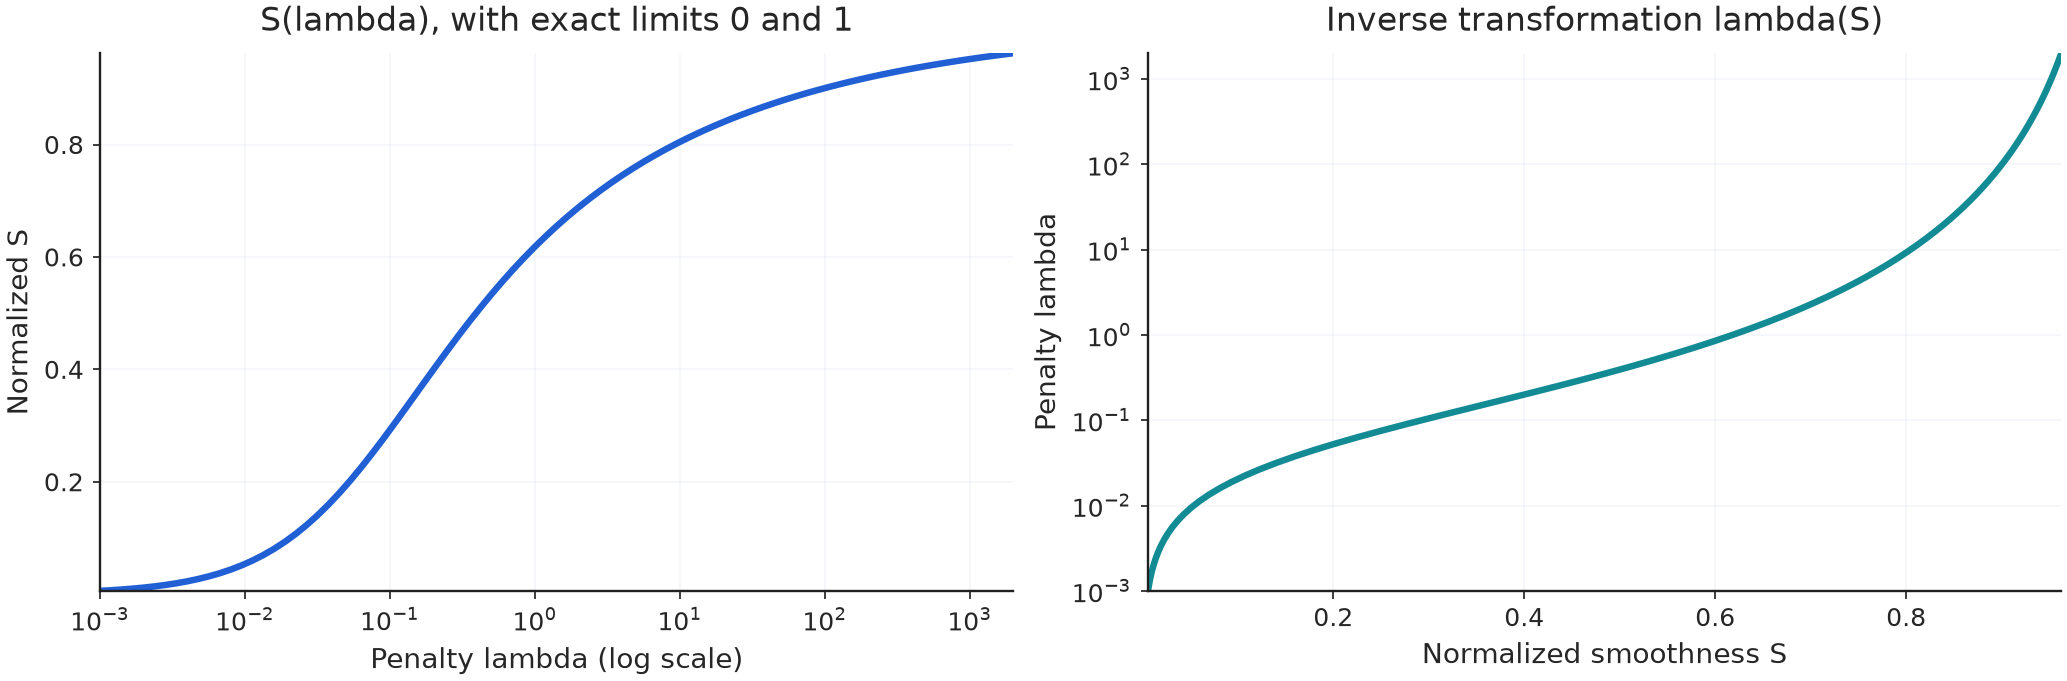

CV: selected lambda=1415.8, S=0.95748, score=0.0787162
GCV: selected lambda=1682.7, S=0.96002, score=0.0791828
AICC: selected lambda=2000, S=0.96245, score=-2.50594
BIC: selected lambda=0.001, S=0.00593, score=-8.34339


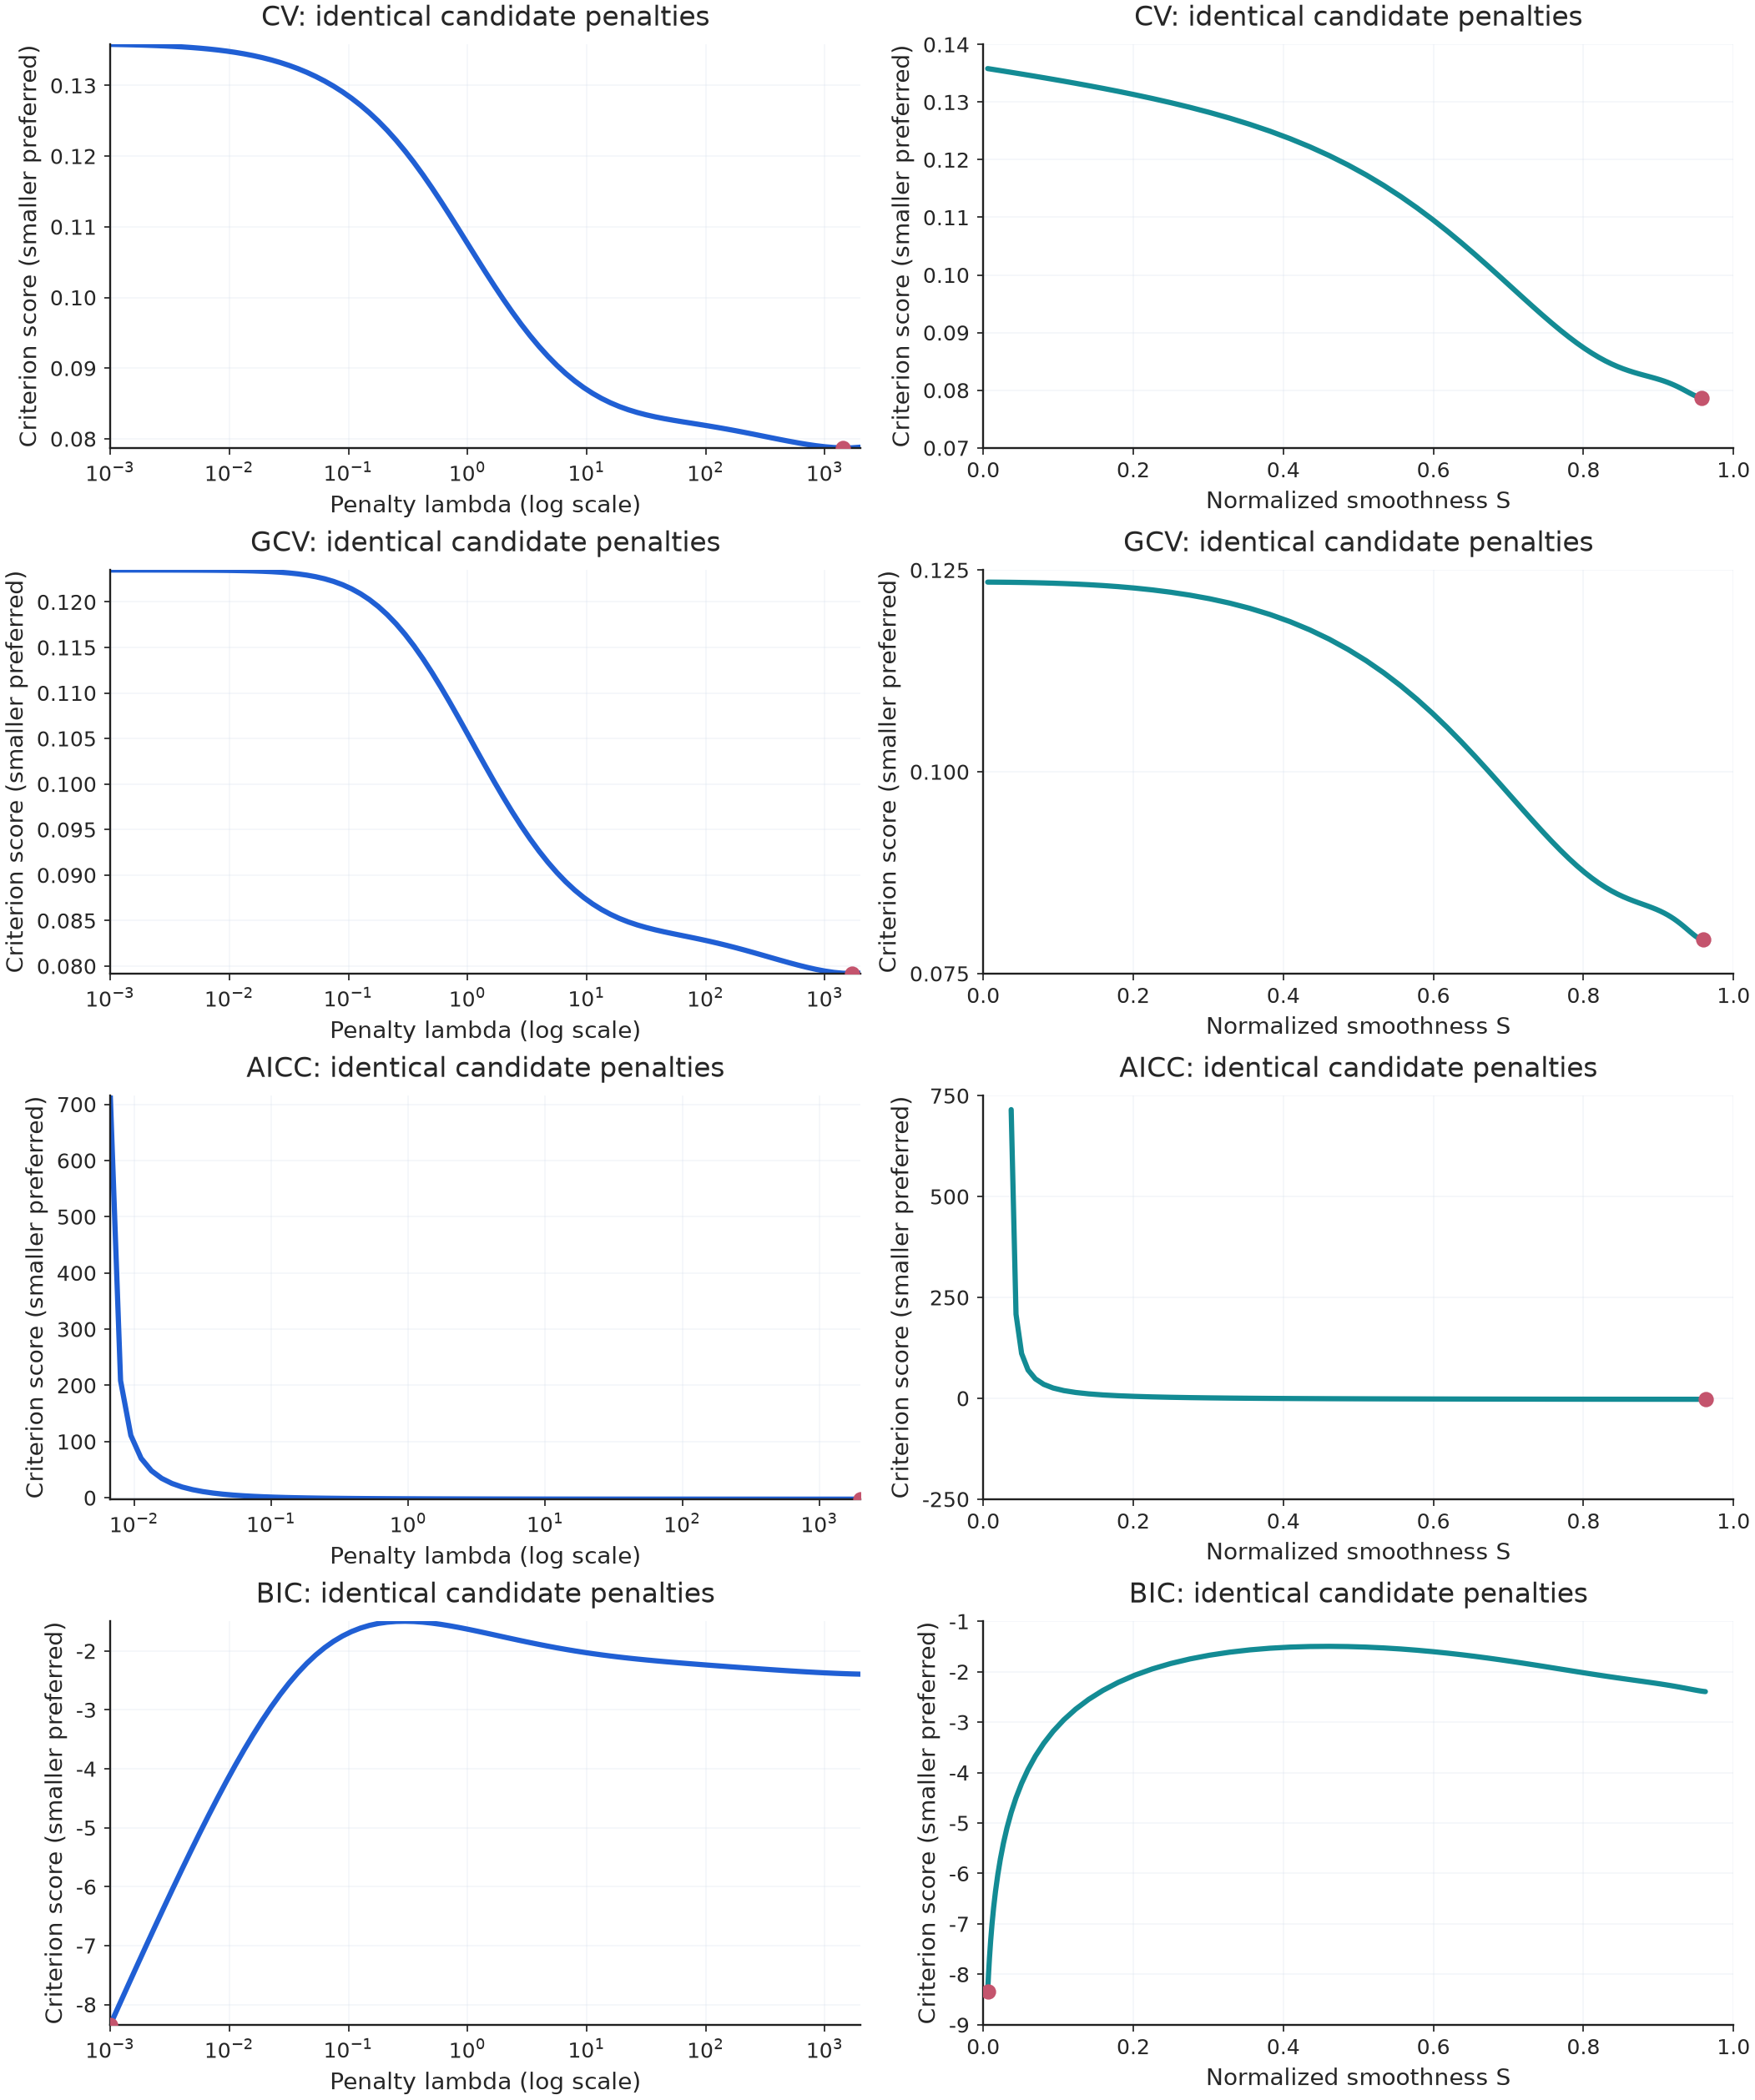

GCV lambda auto-search: 1.918 ms, lambda=1548.9, S=0.95881, score=0.0791891, candidates=122
GCV smoothness auto-search: 26.305 ms, lambda=1499.5, S=0.95833, score=0.0791961, candidates=125


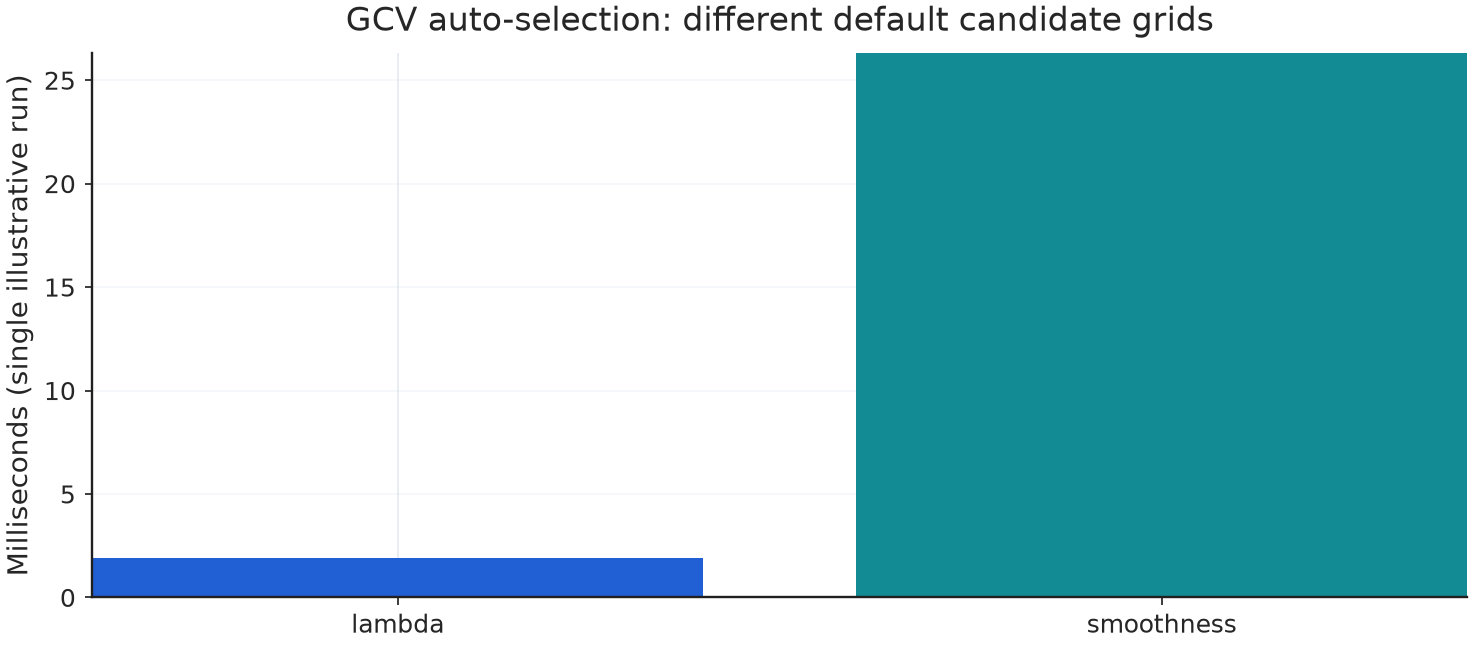

Timing is descriptive, not a controlled speed ranking. See the factorial and public API benchmarks for paired repetitions.


In [6]:
from trendestimation._docs_coordinates import show_dual_coordinate_gallery

_coordinate_series = next((globals()[name] for name in
                           ("history", "y", "observed", "series")
                           if name in globals()), None)
show_dual_coordinate_gallery(_coordinate_series, order=2, mu=0.0)
